# 02 · Preprocessing

Models need numbers on comparable scales, with no hidden answers in them. This notebook runs
the pipeline in [`src/nids/preprocess.py`](../src/nids/preprocess.py) and shows *why* each step exists,
including two live demonstrations of classic mistakes.

| Step | Problem it solves |
|---|---|
| Drop `id`, `attack_cat`, `label` | `id` is meaningless; `attack_cat` and `label` are the answer |
| Validation split (20%, stratified) | A practice exam for tuning, so the test set stays sealed |
| One-hot `proto`, `service`, `state` | Models can't do maths on text like `"tcp"` |
| `log1p` on skewed columns | Byte counts span 28 B to 13 MB; a few giants would dominate |
| Standard scaling | Puts every number on the same scale (mean 0, std 1) |
| **Fit on train only** | Test statistics must never influence the model |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

from nids import config
from nids.data import load_split
from nids.preprocess import prepare, split_xy, build_preprocessor

BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10,
})

## 1. Fit vs. transform: the core idea

Every preprocessing step has two halves:

- **`fit`** *learns* something from data: the list of categories, the mean and standard deviation.
- **`transform`** *applies* what was learned.

**Small example.** Scaling means `(x − mean) / std`. Suppose training `sbytes` values are 100, 200, 300:
mean 200, std ≈ 82. A test flow of 10,000 bytes becomes (10,000 − 200) / 82 ≈ 120: a clear outlier.
If you had fitted on train **+ test**, that 10,000 would have dragged the mean up and shrunk its own
score, so the model is quietly shaped by data it's supposed to have never seen. That's **data leakage**.

In networking terms: you build your baseline of "normal" from last month's traffic, then judge
today's traffic against it. You don't build the baseline *from* the traffic you're judging.

`prepare()` calls `fit_transform` on the training part **once**, then only `transform` on validation and test.

In [2]:
s = prepare()
for name in ["train", "val", "test"]:
    X, y = getattr(s, f"X_{name}"), getattr(s, f"y_{name}")
    print(f"{name:5s} X {str(X.shape):14s} attack share {y.mean():.1%}")

train X (140272, 192)  attack share 68.1%
val   X (35069, 192)   attack share 68.1%
test  X (82332, 192)   attack share 55.1%


The validation set keeps the same **68.1%** attack share as the training part. That's what
`stratify=y` does: without it, a random 20% could by chance contain a different mix.
The test set's 55.1% is the official split, and we don't touch it.

## 2. One-hot encoding

`state` holds text like `FIN`, `INT`, `CON`. You can't put `"FIN"` into an equation, and numbering them
(FIN=1, INT=2, CON=3) would invent a false order: is CON "three times" FIN? One-hot gives each value
its own 0/1 column:

| state | → | state_CON | state_FIN | state_INT |
|---|---|---|---|---|
| FIN | | 0 | 1 | 0 |
| INT | | 0 | 0 | 1 |

Like a VLAN membership bitmap: one bit per VLAN, and a port is either in it or not.

In [3]:
names = pd.Series(s.feature_names)
groups = names.str.extract(r"^(proto|service|state)_")[0].fillna("numeric")
print(groups.value_counts().to_string())
print("total features:", len(names))

0
proto      133
numeric     39
service     13
state        7
total features: 192


In [4]:
# States ACC and CLO only appear in test. handle_unknown="ignore" turns them into all-zero state columns.
test_raw = load_split("test")
X_test_raw, _ = split_xy(test_raw)
state_cols = [i for i, n in enumerate(s.feature_names) if n.startswith("state_")]
unseen = test_raw["state"].isin(["ACC", "CLO"]).to_numpy()
print(f"test rows with an unseen state: {unseen.sum()}")
print("their state_* columns sum to:", s.X_test[unseen][:, state_cols].sum())

test rows with an unseen state: 5
their state_* columns sum to: 0.0


## 3. Log transform, then scaling

Here's one column (`sbytes`) at each stage, on the training data:

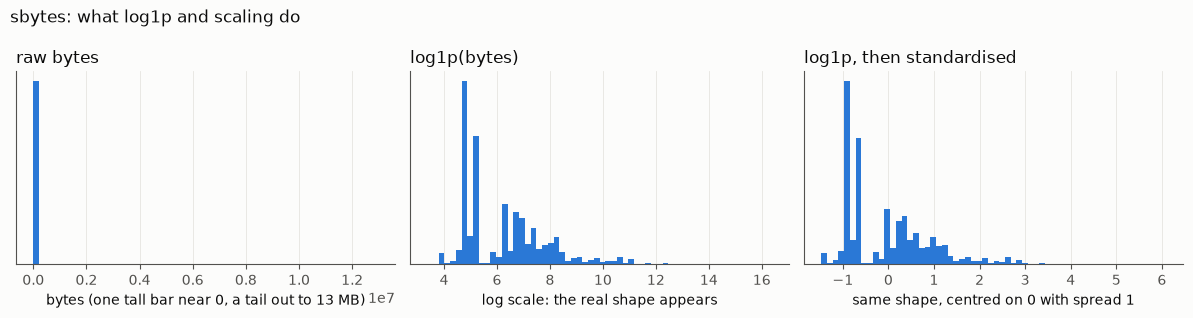

raw:    mean      8,845  std      174,765
scaled: mean      0.000  std        1.000


In [5]:
X_tr_raw, _ = split_xy(load_split("train"))
raw = X_tr_raw["sbytes"].to_numpy()
logged = np.log1p(raw)
scaled = s.X_train[:, s.feature_names.index("sbytes")]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, vals, title in [
    (axes[0], raw, "raw bytes"),
    (axes[1], logged, "log1p(bytes)"),
    (axes[2], scaled, "log1p, then standardised"),
]:
    ax.hist(vals, bins=60, color=BLUE)
    ax.set_title(title, loc="left")
    ax.set_yticks([])
axes[0].set_xlabel("bytes (one tall bar near 0, a tail out to 13 MB)")
axes[1].set_xlabel("log scale: the real shape appears")
axes[2].set_xlabel("same shape, centred on 0 with spread 1")
fig.suptitle("sbytes: what log1p and scaling do", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "02_log_and_scale.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"raw:    mean {raw.mean():>10,.0f}  std {raw.std():>12,.0f}")
print(f"scaled: mean {scaled.mean():>10.3f}  std {scaled.std():>12.3f}")

- **Raw**: nearly every flow piles up in one bar, and 13 MB outliers stretch the axis. A neural network
  would see "small" for almost everything.
- **`log1p`** (`log(1 + x)`; the `+1` keeps 0 bytes valid) spreads them out. Each step on the axis now
  means "×10 more bytes", which is how you'd think about traffic volume anyway.
- **Scaling** centres it at 0 with spread 1, so `sbytes` and `dur` (seconds) are on the same footing.

The **random forest doesn't need any of this**: trees only ask "is sbytes > 430?", and the order of values
is unchanged by log or scaling. The **neural network does**, because it multiplies features by weights.

## 4. Proof that we fitted on train only

In [6]:
num_idx = [i for i, n in enumerate(s.feature_names) if not n.startswith(("proto_", "service_", "state_"))]
for name in ["train", "val", "test"]:
    X = getattr(s, f"X_{name}")[:, num_idx]
    print(f"{name:5s} average column mean {X.mean(axis=0).mean():+.3f}   average column std {X.std(axis=0).mean():.3f}")

train average column mean -0.000   average column std 1.000
val   average column mean +0.000   average column std 1.000
test  average column mean +0.025   average column std 1.001


Train columns have mean **exactly 0** and std **exactly 1**: the scaler learned them from this data.
Validation matches to three decimals because it's a random slice of the same traffic. Test drifts
(average mean around +0.025): a different traffic mix (55% vs 68% attack) the scaler never saw.
**That small gap is the correct, honest result.** If test also showed exactly 0 and 1, it would
mean the scaler had been fitted on test data.

Note the training part has **7** states while the full official train has 9: the single `PAR` and
`URN` rows landed in validation. The encoder only knows categories from the rows it was fitted on.

## 5. ⚠️ Live demo: what leakage looks like

What if we forgot to drop `attack_cat`? A decision tree allowed **one single question** (depth 1):

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

train_raw = load_split("train")
leaky_cols = lambda df: df.drop(columns=[config.ID_COL, config.TARGET])   # attack_cat left in!
pre = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), config.CATEGORICAL + [config.ATTACK_CAT])],
    remainder="passthrough", verbose_feature_names_out=False,
)
Xl_train = pre.fit_transform(leaky_cols(train_raw))
Xl_test = pre.transform(leaky_cols(test_raw))

stump = DecisionTreeClassifier(max_depth=1, random_state=config.RANDOM_STATE)
stump.fit(Xl_train, train_raw[config.TARGET])
print(f"test accuracy with attack_cat leaked: {accuracy_score(test_raw[config.TARGET], stump.predict(Xl_test)):.1%}")
print("the one question it asked:", pre.get_feature_names_out()[stump.tree_.feature[0]], "<= 0.5 ?")

test accuracy with attack_cat leaked: 100.0%
the one question it asked: attack_cat_Normal <= 0.5 ?


**100% with a single question**: "is `attack_cat_Normal` = 0?" The model didn't learn anything about
network traffic. It read the answer off a column that *is* the answer.

**How to spot leakage in the wild:** a score that seems too good, one feature that dominates everything, or
a feature that wouldn't exist at prediction time. In production, nobody hands your IDS a column saying
which attack family a flow belongs to.

## 6. ⚠️ Live demo: never grade on the training data

In [8]:
tree = DecisionTreeClassifier(random_state=config.RANDOM_STATE)   # no depth limit
tree.fit(s.X_train, s.y_train)
print(f"accuracy on the data it trained on: {accuracy_score(s.y_train, tree.predict(s.X_train)):.1%}")
print(f"accuracy on validation:             {accuracy_score(s.y_val, tree.predict(s.X_val)):.1%}")
print(f"tree depth: {tree.get_depth()}, leaves: {tree.get_n_leaves():,}")

accuracy on the data it trained on: 99.8%
accuracy on validation:             94.9%
tree depth: 44, leaves: 4,692


An unlimited tree grows thousands of leaves and **memorises** the training rows. The training score is
nearly perfect and tells you nothing. It's below 100% only because some identical rows carry both labels
(the irreducible error we found in Phase 2). The validation score is the honest one.
This gap is **overfitting**. Phase 4 reports every metric on held-out data only.

## 7. What Phase 4 and 5 receive

| Array | Rows | Used for |
|---|---|---|
| `X_train`, `y_train` | 140,272 | fitting models |
| `X_val`, `y_val` | 35,069 | tuning, early stopping, choosing thresholds |
| `X_test`, `y_test` | 82,332 | **one** final evaluation per model |

`prepare(exclude=config.TTL_COLS)` gives the same arrays without the TTL shortcut features, for the Phase 4 ablation.

## ✏️ Exercise (yours)

Add a test to `tests/test_preprocess.py` called `test_validation_keeps_class_ratio`, using the
`splits` fixture. It should check that the attack share in `y_val` is within 0.5 percentage points of
the share in `y_train`.

- Hint: the attack share of a 0/1 array is just its mean.
- Hint: `pytest.approx(value, abs=0.005)`.
- Don't forget the `@needs_data` decorator. Why does it matter on a fresh clone with no CSVs?

Run `pytest` and paste the test into the chat.